# The solution path

Verification notebook. It reruns the Chapter 5 checks against `lrd`, and produces the two figures. Checks: the barrier bound $D_r\ge D_\infty$ and its rate (V4.1); the first breakpoint against the closed form (V4.4); the $n=3$ $\ell_1$ path in both regimes (V4.5); and the gap-decay rate behind the trichotomy (V4.8).

In [1]:
from lrd.checks import path
from lrd import paths
import numpy as np
import matplotlib.pyplot as plt
from lrd.checks import REGISTRY

## V4.1 — the barrier bound

Every member dominates the endpoint, $D_r(\log x)\ge D_\infty(\log x)$, and $D_\infty(\log x)=\tfrac12\log(x_{\max}/x_{\min})$ grows like $\tfrac12|\log x_{\min}|$ as a coordinate vanishes. This forces every path to stay interior.

In [2]:
path.v4_1()

PASS  V4.1: the barrier bound  [lem:barrier]
    cases with D_r < D_inf (want 0): 0
    t = 1e-02:  D_inf / (0.5|log x_min|) = 0.807
    t = 1e-08:  D_inf / (0.5|log x_min|) = 0.944
    t = 1e-16:  D_inf / (0.5|log x_min|) = 0.971
    t = 1e-40:  D_inf / (0.5|log x_min|) = 0.988
    max |ratio - closed form| = 0.0e+00
  => ratio 0.807 -> 0.988 (closed form to 0e+00); D_r < D_inf in 0 cases

## V4.4 — the first breakpoint in closed form

At $r=\infty$ the path is linear below $\varepsilon_1 = 2\min(\text{top gap}, \text{bottom gap})$, moving only the extremes; at $r=1$ it is the analogous $\ell_1$ segment. We check the solver against the closed-form segment, and that $\varepsilon_1 \le \varepsilon_{\mathrm{sat}}$.

In [3]:
path.v4_4()

PASS  V4.4: the first breakpoint in closed form  [prop:breakpoint, prop:breakpoint1]
    [0.45 0.24 0.16 0.09 0.06]  eps1(r=inf)=0.060  eps1(r=1)=0.070  eps1<=sat: True
    [0.55 0.25 0.13 0.07]  eps1(r=inf)=0.120  eps1(r=1)=0.060  eps1<=sat: True
    [0.3  0.29 0.23 0.18]  eps1(r=inf)=0.020  eps1(r=1)=0.030  eps1<=sat: True
    [0.28 0.27 0.2  0.15 0.1 ]  eps1(r=inf)=0.020  eps1(r=1)=0.050  eps1<=sat: True
    [0.4 0.3 0.2 0.1]  eps1(r=inf)=0.200  eps1(r=1)=0.050  eps1<=sat: True
  => max|solver - closed form| = 5.97e-09 (want < 1e-7); eps1 <= eps_sat: True

## V4.5 — the $n=3$ $\ell_1$ path, both regimes

The exact $n{=}3$ closed form against the solver, at fractions of $\varepsilon_{\mathrm{sat}}$ including past saturation, for case-A and case-B nominals, including the near-degenerate $(0.34,0.33,0.33)$.

In [4]:
path.v4_5()

PASS  V4.5: the n = 3 l1 path, both regimes  [prop:n3]
    [0.7 0.2 0.1]  case A  sat=0.7333  max|diff|=1.4e-09
    [0.5 0.3 0.2]  case A  sat=0.3333  max|diff|=2.5e-10
    [0.4  0.35 0.25]  case B  sat=0.1667  max|diff|=3.7e-10
    [0.45 0.34 0.21]  case B  sat=0.2467  max|diff|=3.5e-09
    [0.34 0.33 0.33]  case A  sat=0.0133  max|diff|=4.4e-09
    [0.5  0.34 0.16]  case B  sat=0.3467  max|diff|=3.9e-09
  => max|solver - closed form| = 4.35e-09; max|sat_B1 - sat_case| = 1.1e-16

## V4.8 — gap decay and the trichotomy

At interior $r$ the minimum coordinate gap never reaches zero before saturation, so there is no breakpoint. As $\varepsilon\to\varepsilon_{\mathrm{sat}}$ it decays linearly in $(1-\varepsilon/\varepsilon_{\mathrm{sat}})$: log-log slope 1 over the last two decades. Members near $r=1$ reach that regime later.

In [5]:
v4_8 = path.v4_8()
v4_8

PASS  V4.8: gap decay, no interior breakpoint  [thm:trichotomy]
    r=1.2: 3.6e-03 1.3e-05 6.9e-07 6.6e-08 6.6e-09   (log-log slope, last 2 decades: 1.010)
    r=1.5: 1.4e-02 1.7e-03 1.5e-04 1.5e-05 1.5e-06   (log-log slope, last 2 decades: 1.002)
    r=2: 1.2e-02 2.8e-03 3.0e-04 3.0e-05 3.0e-06   (log-log slope, last 2 decades: 0.998)
    r=3: 8.2e-03 1.7e-03 1.7e-04 1.7e-05 1.7e-06   (log-log slope, last 2 decades: 0.999)
    r=6: 4.1e-03 6.6e-04 6.5e-05 6.5e-06 6.5e-07   (log-log slope, last 2 decades: 1.000)
    dense r=1.05: min gap 0.0e+00; gap / ||x - u|| from 9.1e-06 to 7.8e-12 (range 0.0e+00-9.1e-06)
    dense r=1.2: min gap 6.6e-09; gap / ||x - u|| from 2.8e-02 to 2.6e-04 (range 2.6e-04-2.8e-02)
    dense r=1.5: min gap 1.5e-06; gap / ||x - u|| from 1.0e-01 to 5.4e-02 (range 5.4e-02-1.0e-01)
    dense r=2: min gap 3.0e-06; gap / ||x - u|| from 7.5e-02 to 9.6e-02 (range 7.5e-02-9.6e-02)
    dense r=3: min gap 1.7e-06; gap / ||x - u|| from 4.4e-02 to 4.5e-02 (range 4.3e-02-4.5e

## V4.2 — the whole $r=\infty$ path is the Ho–Yeung maximum-entropy solution

The $r=\infty$ solution is the maximum-entropy point of an $\ell_1$ ball, which Ho & Yeung (2010) give in closed form. Checked along the whole path, every breakpoint and past saturation included.

In [6]:
path.v4_2()

PASS  V4.2: the r = inf path is the Ho-Yeung maximum-entropy solution  [prop:breakpoint]
  => max|solver - Ho-Yeung| = 1.3e-08 over 994 (nominal, radius) pairs

## V4.3 — the whole $r=1$ path is the box-clip solution

The $r=1$ solution is the maximum-entropy point of an $\ell_\infty$ box intersected with the simplex: a single clipping level.

In [7]:
path.v4_3()

PASS  V4.3: the r = 1 path is the box-clip maximum-entropy solution  [prop:breakpoint1]
  => max|solver - box clip| = 5.6e-09 over 987 (nominal, radius) pairs

## V4.7 — no fusion in smooth balls

For $\ell_s$ balls with $1<s<\infty$ and smooth $f$-divergence balls ($\chi^2$, Hellinger, Kullback–Leibler), the maximum-entropy point keeps the strict order of $\hat p$; total variation and $\ell_\infty$ must fuse on the same nominals. The Kullback–Leibler solution is also checked against the tempered form $\hat p^t/Z$.

In [8]:
path.v4_7()

PASS  V4.7: no fusion in smooth balls; fusion at the kinked endpoints  [prop:nofusion]
    21 nominals (one with a tie), radii at [0.1, 0.3, 0.5, 0.7, 0.9] of the saturation value
     l_1.5: order violations 0, min gap 5.5e-04, tie error 9.1e-10
       l_2: order violations 0, min gap 7.3e-04, tie error 1.2e-09
       l_3: order violations 0, min gap 1.8e-04, tie error 1.2e-09
      chi2: order violations 0, min gap 2.9e-05, tie error 7.8e-10
      hell: order violations 0, min gap 7.7e-04, tie error 1.4e-09
        KL: order violations 0, min gap 5.0e-04, tie error 4.4e-09
    KL ball vs tempered ph^t/Z: max error 5.5e-09
    kinked balls fuse on 20/20 (TV) and 20/20 (l_inf) distinct nominals
  => smooth balls: no fusion (min gap 2.9e-05); TV and l_inf fuse on 20/20 and 20/20

## V4.6 — at $n=3$ the endpoint members coincide

For three numbers that sum to zero, $\lVert d\rVert_\infty = \tfrac12\lVert d\rVert_1$, so $D_1 = 2D_\infty$ and the $r=1$ path at $\varepsilon$ is the $r=\infty$ path at $2\varepsilon$. At $n=4$ the two members differ.

In [9]:
path.v4_6()

PASS  V4.6: at n = 3 the endpoint members coincide  [rem:three]
  => n = 3: max|D_1 - 2 D_inf| = 8.9e-16 over 2000 vectors; max|x_1(eps) - x_inf(2 eps)| = 9.3e-09 over 1008 (nominal, radius) pairs; n = 4: max|D_1 - 2 D_inf| = 3.39

## Figure 1 — the $n=3$ $\ell_1$ path, both regimes

Two simplex triangles: a case-A and a case-B nominal, each showing the straight first phase, the breakpoint where a pair fuses, and the ride along a median to the barycentre. Driven by the exact closed form, so the breakpoint is placed analytically.

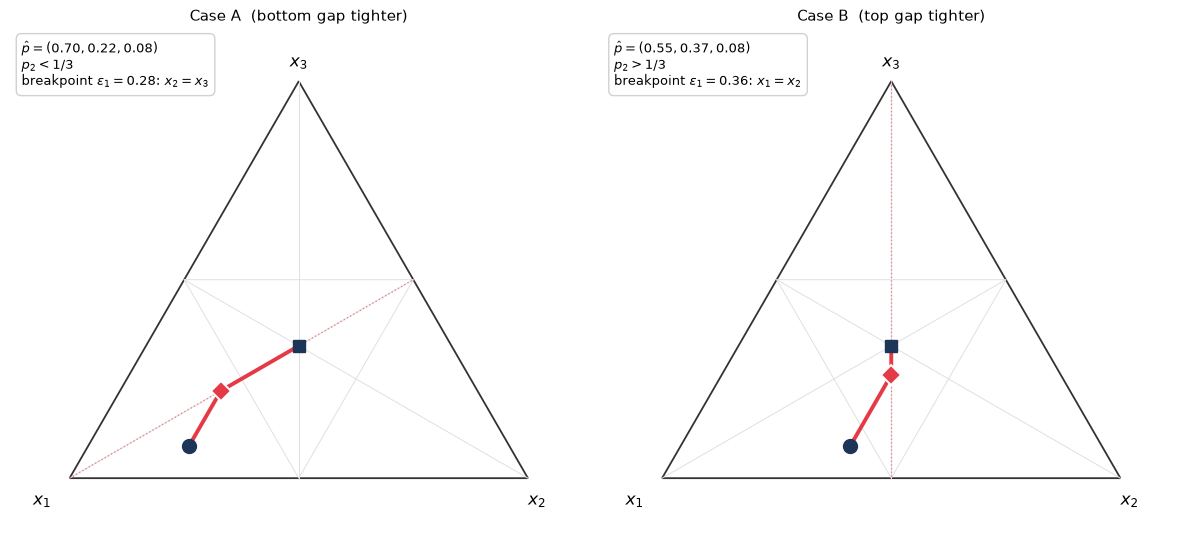

In [10]:
V = np.array([[0, 0], [1, 0], [0.5, np.sqrt(3) / 2]], float)
RED = '#e63946'

def to_cart(p):
    return np.asarray(p) @ V

def draw_simplex(ax):
    ax.add_patch(plt.Polygon(V, fill=False, edgecolor='#333', lw=1.3))
    for (ox, oy), lab in zip([(-.06, -.05), (1.02, -.05), (.5, np.sqrt(3) / 2 + .04)],
                             ['$x_1$', '$x_2$', '$x_3$']):
        ax.text(ox, oy, lab, ha='center', va='center', fontsize=12)
    uu = to_cart([1/3, 1/3, 1/3]); mids = (V + np.roll(V, -1, axis=0)) / 2
    for v in np.vstack([V, mids]):
        ax.plot([uu[0], v[0]], [uu[1], v[1]], color='#e0e0e0', lw=.7, zorder=1)
    ax.add_patch(plt.Polygon(mids, fill=False, edgecolor='#e0e0e0', lw=.7, zorder=1))
    ax.plot(*uu, '+', color='#333', ms=9, mew=1.3, zorder=5); ax.set_aspect('equal'); ax.axis('off')
    ax.set_xlim(-.13, 1.13); ax.set_ylim(-.10, .98)

def panel(ax, ph, tag):
    draw_simplex(ax)
    e1, fuse, apex = path.n3_breakpoint(ph)
    sat = float(np.sum(np.abs(ph - 1/3)))
    eps = np.linspace(0, sat, 400)
    xy = to_cart(np.array([path.n3_path(ph, float(e)) for e in eps]))
    em = (V[fuse[0]] + V[fuse[1]]) / 2
    ax.plot([V[apex][0], em[0]], [V[apex][1], em[1]], color=RED, lw=1, ls=':', alpha=.55, zorder=2)
    k = int(np.sum(eps <= e1))
    ax.plot(*xy[:k].T, color=RED, lw=2.8, zorder=4); ax.plot(*xy[k-1:].T, color=RED, lw=2.8, zorder=4)
    ax.plot(*to_cart(ph), 'o', color='#1d3557', ms=10, zorder=7)
    ax.plot(*to_cart(path.n3_path(ph, e1)), 'D', color=RED, ms=10, mec='white', mew=1.4, zorder=8)
    ax.plot(*to_cart(np.ones(3) / 3), 's', color='#1d3557', ms=9, zorder=7)
    fused = 'x_2=x_3' if apex == 0 else 'x_1=x_2'
    ax.text(.02, .98, f'$\\hat p=({ph[0]:.2f},{ph[1]:.2f},{ph[2]:.2f})$\n'
            f'$p_2{"<" if ph[1] < 1/3 else ">"}1/3$\nbreakpoint $\\varepsilon_1={e1:.2f}$: ${fused}$',
            transform=ax.transAxes, va='top', fontsize=9.5,
            bbox=dict(boxstyle='round,pad=.4', fc='white', ec='#ccc', alpha=.9))
    ax.set_title(tag, fontsize=11)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
panel(axes[0], np.array([0.70, 0.22, 0.08]), 'Case A  (bottom gap tighter)')
panel(axes[1], np.array([0.55, 0.37, 0.08]), 'Case B  (top gap tighter)')
fig.tight_layout(); fig.savefig(paths.figure('fig_simplex_path.pdf'), bbox_inches='tight')
plt.show()

## Figure 2 — gap decay at interior $r$

The minimum coordinate gap against $1-\varepsilon/\varepsilon_{\mathrm{sat}}$, log-log. The straight lines are the linear rate: no gap reaches zero before saturation, so no interior member has a breakpoint.

saved fig_gap_decay.pdf


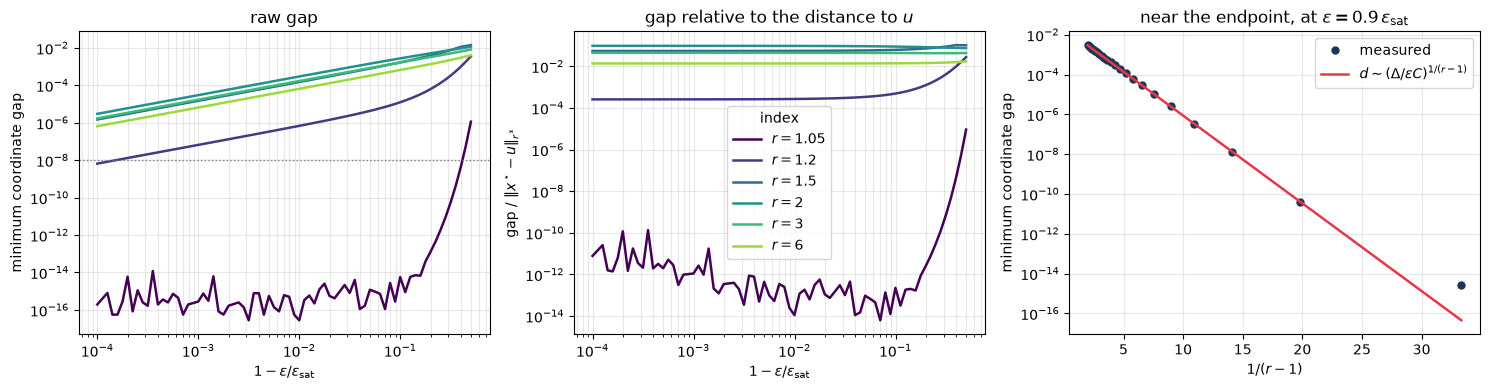

In [11]:
d = v4_8.data
d9 = REGISTRY['V4.9']().data
xax = 1 - np.array(d['dense'])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = plt.cm.viridis(np.linspace(0, .85, len(d['raw'])))
for (r, raw), c in zip(d['raw'].items(), colors):
    raw = np.array(raw); rel = np.array(d['rel'][r]); ok = raw > 0
    axes[0].loglog(xax[ok], raw[ok], '-', color=c, lw=1.8, label=f'$r={r}$')
    axes[1].loglog(xax[ok], rel[ok], '-', color=c, lw=1.8, label=f'$r={r}$')
axes[0].axhline(1e-8, color='gray', ls=':', lw=1)
axes[0].set_ylabel('minimum coordinate gap'); axes[0].set_title('raw gap')
axes[1].set_ylabel(r'gap / $\|x^\star - u\|_{r^*}$'); axes[1].set_title('gap relative to the distance to $u$')
for ax in axes[:2]:
    ax.set_xlabel(r'$1-\varepsilon/\varepsilon_{\mathrm{sat}}$'); ax.grid(alpha=.3, which='both')
axes[1].legend(title='index', fontsize=10)
rs = np.array(d9['rs']); dd = np.array(d9['d']); inv = 1/(rs-1)
m, b = d9['slope'], d9['intercept']
axes[2].semilogy(inv, dd, 'o', color='#1d3557', ms=5, label='measured')
xs = np.linspace(inv.min(), inv.max(), 50)
axes[2].semilogy(xs, 10**(m*xs+b), '-', color='#e63946', lw=1.8, label=r'$d\sim(\Delta/\varepsilon C)^{1/(r-1)}$')
axes[2].set_xlabel(r'$1/(r-1)$'); axes[2].set_ylabel('minimum coordinate gap')
axes[2].set_title(r'near the endpoint, at $\varepsilon=0.9\,\varepsilon_{\mathrm{sat}}$')
axes[2].grid(alpha=.3, which='both'); axes[2].legend(fontsize=10)
fig.tight_layout(); fig.savefig(paths.figure('fig_gap_decay.pdf'), bbox_inches='tight')
print('saved fig_gap_decay.pdf')